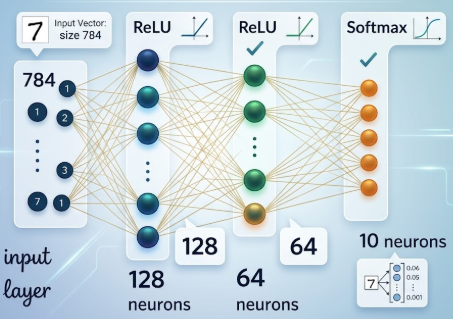

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

In [2]:
torch.manual_seed(42)

In [3]:
df = pd.read_csv('fmnist_small.csv')
df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,9,0,0,0,0,0,0,0,0,0,...,0.0,7.0,0.0,50.0,205.0,196.0,213.0,165.0,0.0,0.0
1,7,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0,0,0,0,0,0,1,0,0,0,...,142.0,142.0,142.0,21.0,0.0,3.0,0.0,0.0,0.0,0.0
3,8,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,8,0,0,0,0,0,0,0,0,0,...,213.0,203.0,174.0,151.0,188.0,10.0,0.0,0.0,0.0,0.0


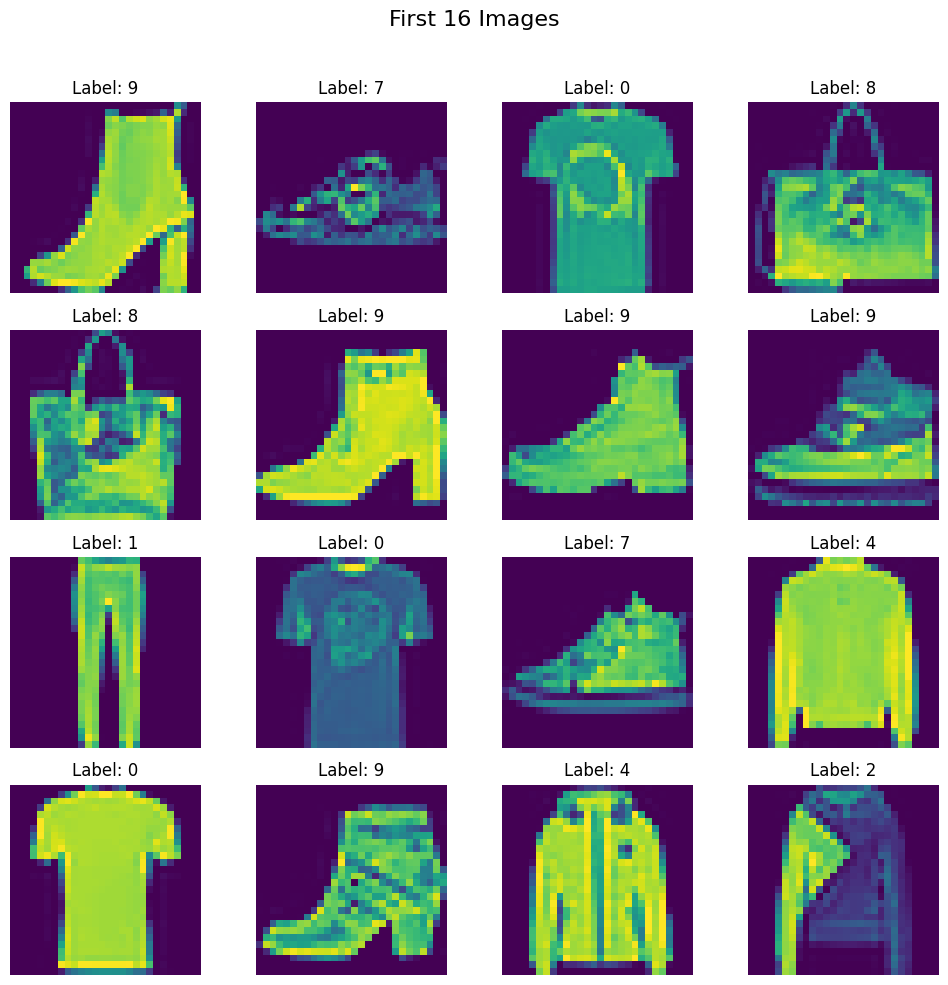

In [4]:
# Create a 4x4 grid of images
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
fig.suptitle("First 16 Images", fontsize=16)

# Plot the first 16 images from the dataset
for i, ax in enumerate(axes.flat):
    img = df.iloc[i, 1:].values.reshape(28, 28)  # Reshape to 28x28
    ax.imshow(img)  # Display in grayscale
    ax.axis('off')  # Remove axis for a cleaner look
    ax.set_title(f"Label: {df.iloc[i, 0]}")  # Show the label

plt.tight_layout(rect=[0, 0, 1, 0.96])  # Adjust layout to fit the title
plt.show()

In [5]:
# train test split

X = df.iloc[:, 1:].values
y = df.iloc[:, 0].values

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [7]:
# scaling the feautures
X_train = X_train/255.0
X_test = X_test/255.0

In [8]:
X_train

array([[0.        , 0.        , 0.        , ..., 0.01176471, 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 0.        , 0.01960784,
        0.00392157],
       [0.        , 0.        , 0.        , ..., 0.0627451 , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ]])

In [9]:
class CustomDataset(Dataset):
  def __init__(self,feautures,labels):
    self.feautures = torch.tensor(feautures,dtype=torch.float32)
    self.labels = torch.tensor(labels,dtype=torch.long)

  def __len__(self):
    return len(self.feautures)

  def __getitem__(self,idx):
    return self.feautures[idx],self.labels[idx]



In [10]:
train_dataset = CustomDataset(X_train, y_train)

In [11]:
train_dataset[0]

(tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0118, 0.2745, 0.5216, 0.3529, 0.4000, 0.4196, 0.3412, 0.5608, 0.4745,
         0.0510, 0.0235, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.2000,
         0.3922, 0.3216, 0.3255, 0.4863, 0.4510, 0.3529, 0.4118, 0.4549, 0.6275,
         0.3686, 0.2784, 0.3176, 0.2431, 0.0275, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.2392,
         0.4118, 0.2353, 0.2235, 0.2078, 0.2039, 0.2235, 0.2196, 0.2902, 0.2353,
         0.1608, 0.1765, 0.2039, 0.2039, 0.2784, 0.3255, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0588,
         0.3843, 0.2941, 0.3059, 0.2078, 0.2431, 0.2588, 0.2431, 0.2235, 0.2196,
         0.2078, 0.2039, 0.2078, 0.2353, 0.2392, 0.2235, 0.2745, 0.2118, 0.0000,
         0.0000, 0.0000, 0.0

In [12]:
test_dataset = CustomDataset(X_test, y_test)

In [13]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [14]:
class MyNN(nn.Module):

  def __init__(self, num_features):

    super().__init__()
    self.model = nn.Sequential(
        nn.Linear(num_features, 128),
        nn.ReLU(),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 10)
    )

  def forward(self, x):

    return self.model(x)

In [15]:
epochs = 100
learning_rate = 0.1


In [16]:
model = MyNN(X_train.shape[1])

In [17]:
criterion = nn.CrossEntropyLoss()

In [18]:
optimizer = optim.SGD(model.parameters(), lr= learning_rate)

In [19]:
len(train_loader)

83

In [20]:
for epoch in range(epochs):

  total_epoch_loss = 0

  for batch_features, batch_labels in train_loader:

    # forward pass
    outputs = model(batch_features)

    # calculate loss
    loss = criterion(outputs, batch_labels)

    # back pass
    optimizer.zero_grad()
    loss.backward()

    # update grads
    optimizer.step()

    total_epoch_loss = total_epoch_loss + loss.item()

  avg_loss = total_epoch_loss/len(train_loader)
  print(f'Epoch: {epoch + 1} , Loss: {avg_loss}')

Epoch: 1 , Loss: 1.6270991527890584
Epoch: 2 , Loss: 0.9283026607639818
Epoch: 3 , Loss: 0.7757640883146998
Epoch: 4 , Loss: 0.6970971639615944
Epoch: 5 , Loss: 0.6270412562123264
Epoch: 6 , Loss: 0.5788940374391625
Epoch: 7 , Loss: 0.549733421529632
Epoch: 8 , Loss: 0.5142801014414753
Epoch: 9 , Loss: 0.4983375366911831
Epoch: 10 , Loss: 0.47906181350888977
Epoch: 11 , Loss: 0.45913528839507733
Epoch: 12 , Loss: 0.4393522667597575
Epoch: 13 , Loss: 0.40801331885607844
Epoch: 14 , Loss: 0.40396787585264227
Epoch: 15 , Loss: 0.3672593578875783
Epoch: 16 , Loss: 0.3676378270050129
Epoch: 17 , Loss: 0.35238678950861274
Epoch: 18 , Loss: 0.3321196106543024
Epoch: 19 , Loss: 0.33721189173948335
Epoch: 20 , Loss: 0.3009537338133318
Epoch: 21 , Loss: 0.3175183633364827
Epoch: 22 , Loss: 0.3034684958766742
Epoch: 23 , Loss: 0.27869696295764074
Epoch: 24 , Loss: 0.28325232710823955
Epoch: 25 , Loss: 0.2547159144677312
Epoch: 26 , Loss: 0.2516304930470076
Epoch: 27 , Loss: 0.24447130205401454
Ep

In [21]:
model.eval()

MyNN(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [22]:
total = 0
correct = 0

with torch.no_grad():

  for batch_features, batch_labels in test_loader:

    outputs = model(batch_features)

    _, predicted = torch.max(outputs, 1)

    total = total + batch_labels.shape[0]

    correct = correct + (predicted == batch_labels).sum().item()

print(correct/total)


0.8318181818181818


In [23]:
len(test_loader)

21